# 02 — ROI orientation and coordinate EDA (PNG-only, VS Code repo layout)

**Person 2 | Cardiac fibrosis dataset | Person 3 handoff**

Save this notebook at `D37-Semantic-Data-Lake/EDA/02_roi_orientation_eda.ipynb` and run it in VS Code. The repository root is configured explicitly below, so the notebook works even when VS Code starts its kernel in `EDA/`. It locates the repository using the input directory structure (or `REPO_ROOT_OVERRIDE` below), and reads **already extracted** inputs:

- `Images/outputs/tables/image_handoff.csv`
- `Images/outputs/previews/<sample>_C1.png` (or overlay fallback)
- `datasets/ventricular data/ROIvalues/*.txt`
- `datasets/ventricular data/orientationStack.txt`
- `datasets/ventricular data/fibrosisAnalysis.m`

No ZIP files or `.lif` files are required. Generated results are written to `<repo>/Person2_ROI_Orientation/`, including `Person3_Handoff_PNG_only.zip`.

**Important:** PNG overlays are provisional visual QC. They are not native-resolution crops or quantitative microscopy data. Manual ROI review and native alignment remain necessary for downstream fibrosis measurements.

In [1]:
# Install packages in your VS Code notebook kernel once if needed:
# %pip install numpy pandas matplotlib pillow scipy
from pathlib import Path
import zipfile, re, io, json, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy.ndimage import rotate
from IPython.display import display

# Repository root: notebook lives in <repo>/EDA/, but inputs are relative to <repo>.
# Change this only if you move or rename the repository.
REPO_ROOT_OVERRIDE = Path('/Users/vaidehikarve/Documents/D37-Semantic-Data-Lake')

def is_repo_root(p):
    return ((p/'Images'/'outputs'/'previews').is_dir()
            and (p/'datasets'/'ventricular data'/'ROIvalues').is_dir())

def locate_repo():
    if REPO_ROOT_OVERRIDE is not None:
        p=Path(REPO_ROOT_OVERRIDE).expanduser().resolve()
        if not is_repo_root(p): raise FileNotFoundError(f'Expected extracted project folders under {p}')
        return p
    candidates = [Path.cwd(), *Path.cwd().parents,
                  Path.home()/'Documents'/'D37-Semantic-Data-Lake']
    for p in candidates:
        if is_repo_root(p): return p.resolve()
    raise FileNotFoundError('Could not find D37-Semantic-Data-Lake. Set REPO_ROOT_OVERRIDE in this cell.')

REPO_ROOT=locate_repo()
OUTPUTS_DIR=REPO_ROOT/'Images'/'outputs'
PREVIEW_DIR=OUTPUTS_DIR/'previews'
VENTRICULAR_DIR=REPO_ROOT/'datasets'/'ventricular data'
ROI_DIR=VENTRICULAR_DIR/'ROIvalues'
for path in (OUTPUTS_DIR/'tables'/'image_handoff.csv',
             VENTRICULAR_DIR/'orientationStack.txt', VENTRICULAR_DIR/'fibrosisAnalysis.m'):
    if not path.is_file(): raise FileNotFoundError(f'Missing input: {path}')
if not list(ROI_DIR.glob('*.txt')):
    raise FileNotFoundError(f'No ROI .txt files found in {ROI_DIR}')
OUT=REPO_ROOT/'Person2_ROI_Orientation'
TABLES=OUT/'data'/'processed'; FIGS=OUT/'outputs'/'figures'; OVERLAYS=FIGS/'roi_overlays'; DOCS=OUT/'docs'
HANDOFF=OUT/'Person3_Handoff'
for folder in (TABLES,FIGS,OVERLAYS,DOCS,HANDOFF): folder.mkdir(parents=True,exist_ok=True)
print('Repository:',REPO_ROOT)
print('Preview directory:',PREVIEW_DIR)
print('ROI directory:',ROI_DIR)
print('Output directory:',OUT)


Repository: /Users/vaidehikarve/Documents/D37-Semantic-Data-Lake
Preview directory: /Users/vaidehikarve/Documents/D37-Semantic-Data-Lake/Images/outputs/previews
ROI directory: /Users/vaidehikarve/Documents/D37-Semantic-Data-Lake/datasets/ventricular data/ROIvalues
Output directory: /Users/vaidehikarve/Documents/D37-Semantic-Data-Lake/Person2_ROI_Orientation


## 1. Load Person 1 metadata and original study list

In [2]:
def read_handoff():
    path=OUTPUTS_DIR/'tables'/'image_handoff.csv'
    return pd.read_csv(path)

images = read_handoff().copy()
assert images['sample_id'].is_unique and images['sample_id'].notna().all()
assert (images[['width_px','height_px']] > 0).all().all()

matlab = (VENTRICULAR_DIR / 'fibrosisAnalysis.m').read_text(errors='replace')
# Source MATLAB uses one cell-array row per sample, with group/etiology/channel fields.
entries = []
for line in matlab.splitlines():
    match = re.search(r"\{'([^']+_overview)'\s*,(.*)\}", line)
    if not match: continue
    sid, remainder = match.groups()
    tokens = re.findall(r"'([^']*)'", remainder)
    d = {'sample_id': sid}
    for key, value in zip(tokens[::2], tokens[1::2]): d[key] = value
    entries.append(d)
study = pd.DataFrame(entries).drop_duplicates('sample_id')
assert len(study) == 21, f'Expected 21 study entries, found {len(study)}; inspect MATLAB parsing.'
assert study['sample_id'].is_unique
images = images.merge(study, on='sample_id', how='left', validate='one_to_one', indicator='matlab_match')
images['included_in_study'] = images['matlab_match'].eq('both')
images['study_group'] = images['group'].fillna('Unlisted')
print('Inventory:',len(images),'MATLAB study:',len(study),'unlisted:',images.loc[~images.included_in_study,'sample_id'].tolist())
display(images[['sample_id','width_px','height_px','included_in_study','study_group']].head())


Inventory: 22 MATLAB study: 21 unlisted: ['190913_1_overview']


,sample_id,width_px,height_px,included_in_study,study_group
0,190913_1_overview,5608,4807,False,Unlisted
1,190930_1_overview,15525,10968,True,HF
2,191007_1_overview,9368,12080,True,HF
3,191007_2_overview,10308,9314,True,HF
4,191017_1_overview,17675,9314,True,HF


## 2. Read all ROI vertices and orientation entries

In [3]:
roi_rows=[]
paths=sorted(ROI_DIR.glob('*.txt'))
for p in paths:
    sid=p.stem
    raw=p.read_text(encoding='utf-8-sig',errors='replace')
    coords=np.genfromtxt(io.StringIO(raw), dtype=float)
    row={'sample_id':sid,'roi_source':str(p.relative_to(REPO_ROOT)),
         'coordinate_rows_valid':coords.shape==(4,2)}
    if coords.shape==(4,2):
        for j,(x,y) in enumerate(coords,1):
            row[f'x{j}']=x
            row[f'y{j}']=y
    roi_rows.append(row)
roi=pd.DataFrame(roi_rows)
assert roi.sample_id.is_unique
orientation=pd.read_csv(VENTRICULAR_DIR/'orientationStack.txt',sep=r'\s+',engine='python')
orientation=orientation.rename(columns={'filename':'orientation_id','angle':'rotation_angle_deg'})
orientation['sample_id']=orientation['orientation_id'].astype(str).str.replace(r'_overview$','',regex=True)+'_overview'
assert orientation.sample_id.is_unique, 'Duplicate orientation IDs'
orientation['rotation_angle_deg']=pd.to_numeric(orientation.rotation_angle_deg,errors='coerce')
print('ROI records:',len(roi),'orientation records:',len(orientation))
print('Missing orientation angles:',orientation.rotation_angle_deg.isna().sum())


ROI records: 22 orientation records: 22
Missing orientation angles: 0


## 3. Match records and validate MATLAB ROI crop convention (metadata-only checks)

The script uses `xLim=[cord(1,1),cord(2,1)]`, `yLim=[cord(1,2),cord(3,2)]`, then subtracts 1 from the end coordinates. In Python this is `image[y1-1:y3-1, x1-1:x2-1]` (end exclusive). After `flipud`, the −90° rotation exchanges width and height; the final arbitrary-angle rotation uses **crop** mode and preserves those swapped dimensions. MATLAB uses 1-based indices.

**Important:** A coordinate flag is not automatically a bad ROI: it may reflect source coordinate-frame differences. Do not force it into bounds or silently clip.


In [4]:
df=images.merge(roi,on='sample_id',how='left',validate='one_to_one').merge(
    orientation[['sample_id','rotation_angle_deg']],on='sample_id',how='left',validate='one_to_one')
xy=[f'{a}{j}' for j in range(1,5) for a in 'xy']

def validate(r):
    values=np.array([r.get(c,np.nan) for c in xy],dtype=float)
    finite=np.isfinite(values).all()
    if not finite: return pd.Series({'roi_valid':False,'validation_issue':'missing_or_nonnumeric_coordinates'})
    p=values.reshape(4,2)
    ints=np.all(np.equal(p,np.round(p)))
    rect=(p[0,1]==p[1,1] and p[1,0]==p[2,0] and p[2,1]==p[3,1] and p[3,0]==p[0,0])
    x1,y1=p[0];x2=p[1,0];y3=p[2,1]
    positive=(x2>x1 and y3>y1)
    # post-flip, post--90 rotation, before arbitrary angle with 'crop': width = original height
    bounds=(x1>=1 and y1>=1 and x2-1<=r['height_px'] and y3-1<=r['width_px'])
    flags=[]
    if not ints: flags.append('noninteger')
    if not rect: flags.append('not_expected_rectangle_order')
    if not positive: flags.append('nonpositive_extent')
    if not bounds: flags.append('outside_transformed_bounds')
    if pd.isna(r['rotation_angle_deg']): flags.append('missing_orientation')
    return pd.Series({'roi_valid':len(flags)==0,'validation_issue':';'.join(flags) if flags else 'none',
                      'roi_width_px':x2-x1,'roi_height_px':y3-y1,
                      'transformed_width_px':r['height_px'],'transformed_height_px':r['width_px']})
checks=df.apply(validate,axis=1)
df=pd.concat([df,checks],axis=1)
assert df.sample_id.is_unique
print('Valid ROIs:',df.roi_valid.sum(),'/',len(df))
display(df.loc[~df.roi_valid,['sample_id','validation_issue']])


Valid ROIs: 17 / 22


,sample_id,validation_issue
4,191017_1_overview,outside_transformed_bounds
10,191125_1_overview,outside_transformed_bounds
17,200219_1_overview,outside_transformed_bounds
18,200318_1_overview,outside_transformed_bounds
19,200318_2_overview,outside_transformed_bounds


## 4. Geometry, orientation and output tables

In [5]:
df['roi_area_px2']=df.roi_width_px*df.roi_height_px
df['roi_area_mm2']=df.roi_area_px2*df.pixel_size_x_um*df.pixel_size_y_um/1e6
df['roi_coverage_pct']=100*df.roi_area_px2/(df.width_px*df.height_px)
df['centroid_x_transformed']=(df.x1+df.x2-1)/2
df['centroid_y_transformed']=(df.y1+df.y3-1)/2
df['roi_area_review_flag']=df.roi_area_mm2.notna() & ((df.roi_area_mm2<0.8)|(df.roi_area_mm2>1.2))
df['visual_review_status']='pending'
df['transform_validation_status']='metadata_only_not_native_verified'
coord_cols=['sample_id','included_in_study','roi_source','coordinate_rows_valid']+xy
valid_cols=['sample_id','included_in_study','roi_valid','validation_issue','transformed_width_px','transformed_height_px','visual_review_status','transform_validation_status']
geom_cols=['sample_id','included_in_study','roi_width_px','roi_height_px','roi_area_px2','roi_area_mm2','roi_coverage_pct','centroid_x_transformed','centroid_y_transformed','roi_area_review_flag']
orient_cols=['sample_id','included_in_study','rotation_angle_deg']
df[coord_cols].to_csv(TABLES/'roi_coordinates.csv',index=False)
df[valid_cols].to_csv(TABLES/'roi_validation.csv',index=False)
df[geom_cols].to_csv(TABLES/'roi_geometry.csv',index=False)
df[orient_cols].to_csv(TABLES/'orientation_metadata.csv',index=False)
print('Saved four primary CSVs')


Saved four primary CSVs


## 5. EDA figures

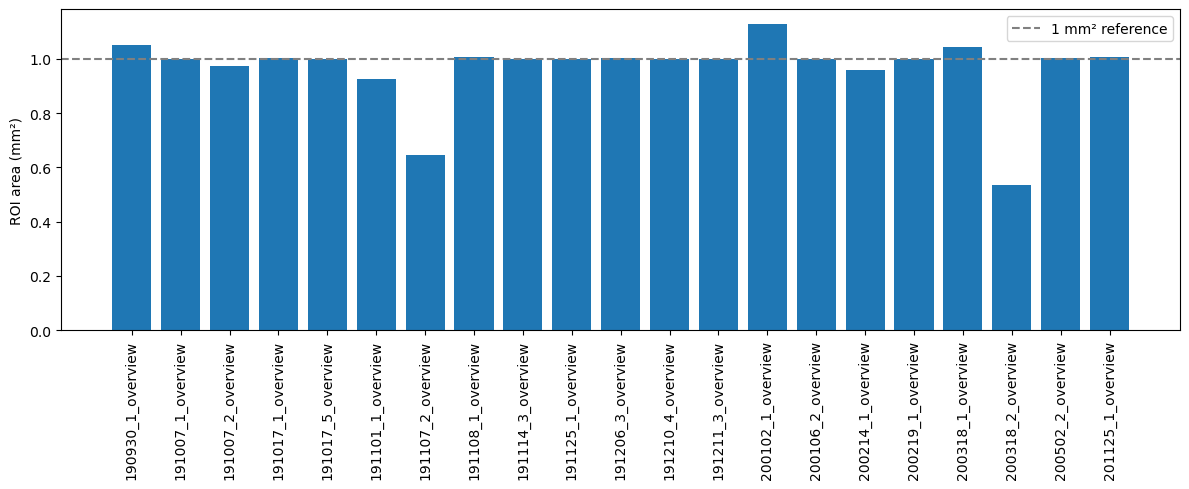

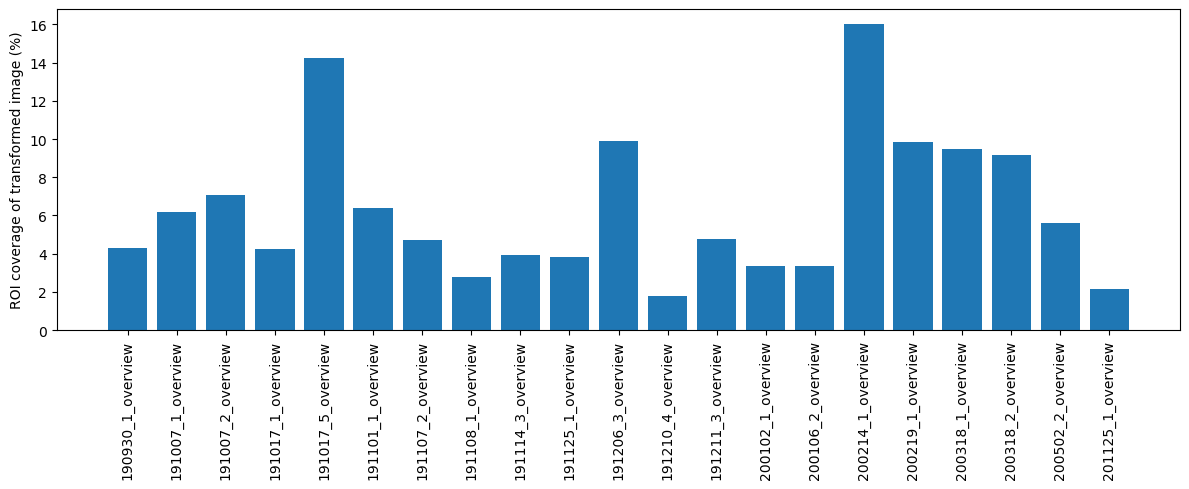

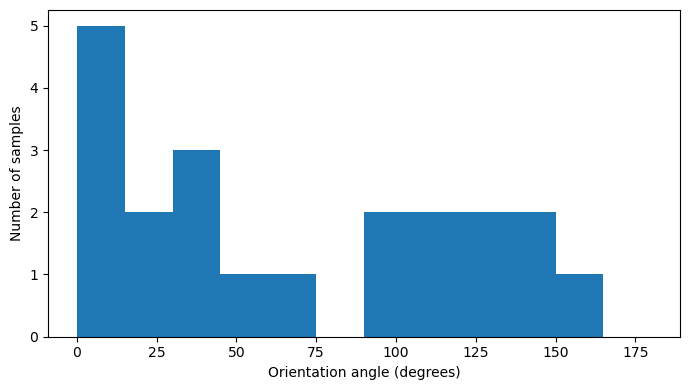

In [6]:
stud=df[df.included_in_study].sort_values('sample_id')
fig,ax=plt.subplots(figsize=(12,5));ax.bar(stud.sample_id,stud.roi_area_mm2);ax.axhline(1,ls='--',color='gray',label='1 mm² reference');ax.tick_params(axis='x',rotation=90);ax.set_ylabel('ROI area (mm²)');ax.legend();fig.tight_layout();fig.savefig(FIGS/'roi_area_distribution.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(12,5));ax.bar(stud.sample_id,stud.roi_coverage_pct);ax.tick_params(axis='x',rotation=90);ax.set_ylabel('ROI coverage of transformed image (%)');fig.tight_layout();fig.savefig(FIGS/'roi_coverage_distribution.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(7,4));ax.hist(stud.rotation_angle_deg.dropna(),bins=np.arange(0,181,15));ax.set(xlabel='Orientation angle (degrees)',ylabel='Number of samples');fig.tight_layout();fig.savefig(FIGS/'orientation_distribution.png',dpi=160);plt.show()


## 6. PNG-only provisional ROI overlays and orientation comparisons

Use Person 1's PNGs from `Images/outputs/previews/`. Select `_C1.png` for a consistent single-channel grayscale background, with `_overlay.png` as fallback. These previews are display-scaled and downsampled; rotate only for visualization. All 22 ROI locations are drawn, including **flagged ROIs**, so that flags can be investigated. The red border indicates a metadata validation issue; green indicates metadata checks passed. A dashed rectangle can be partially off-image, which is intentional.

**Scaling:** after the 90° rotation, map original transformed coordinates to preview coordinates separately along X and Y, based on the native dimensions from Person 1. These overlays are **not exact MATLAB equivalents**; preview downsampling and SciPy interpolation differ from native MATLAB processing.


Preview overlays created: 22 of 22


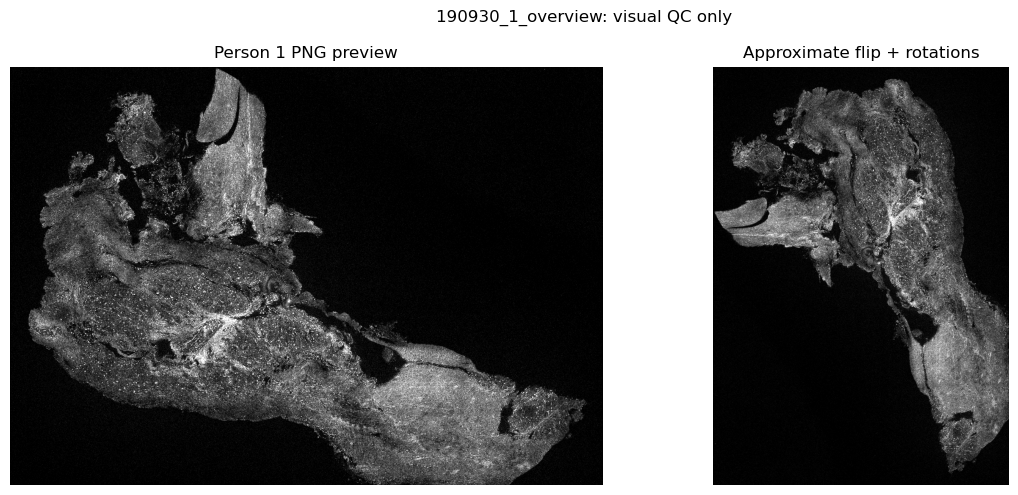

In [7]:
def preview_bytes(sample_id):
    names=[f'{sample_id}_C1.png',f'{sample_id}_overlay.png']
    for name in names:
        file=PREVIEW_DIR/name
        if file.is_file(): return file.read_bytes(),name
    return None,None

def get_preview(sample_id):
    raw,name=preview_bytes(sample_id)
    if raw is None:return None,None
    return np.asarray(Image.open(io.BytesIO(raw)).convert('RGB')),name

def transform_preview(arr,angle):
    a=np.rot90(np.flipud(arr),k=-1)
    if pd.notna(angle) and float(angle)!=0:
        a=rotate(a,-float(angle),axes=(1,0),reshape=False,order=1,mode='constant',cval=0)
    return np.clip(a,0,255).astype('uint8')

preview_results=[]
for r in df.itertuples(index=False):
    preview,preview_name=get_preview(r.sample_id)
    record={'sample_id':r.sample_id,'preview_file':preview_name,'preview_found':preview is not None,
            'preview_overlay_created':False,'preview_overlay_path':'', 'preview_review_status':'pending_manual_review'}
    if preview is None or not pd.notna(r.rotation_angle_deg):
        preview_results.append(record);continue
    a=transform_preview(preview,r.rotation_angle_deg)
    h,w=a.shape[:2]
    sx=w/r.transformed_width_px;sy=h/r.transformed_height_px
    fig,ax=plt.subplots(figsize=(8,7));ax.imshow(a)
    if all(np.isfinite([r.x1,r.y1,r.x2,r.y3])):
        x0=(r.x1-1)*sx; y0=(r.y1-1)*sy
        x1=(r.x2-1)*sx; y1=(r.y3-1)*sy
        rect=Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor=('lime' if r.roi_valid else 'red'),linewidth=2,linestyle=('--' if not r.roi_valid else '-'))
        ax.add_patch(rect)
    ax.set_xlim(0,w);ax.set_ylim(h,0)
    ax.set_title(f'{r.sample_id} | {r.rotation_angle_deg:g}° | {"metadata PASS" if r.roi_valid else "FLAG: "+str(r.validation_issue)}',fontsize=10)
    ax.axis('off');fig.tight_layout()
    dest=OVERLAYS/f'{r.sample_id}_roi_overlay.png'
    fig.savefig(dest,dpi=120);plt.close(fig)
    record.update(preview_overlay_created=True,preview_overlay_path=str(dest.relative_to(OUT)))
    preview_results.append(record)
preview_qc=pd.DataFrame(preview_results)
preview_qc.to_csv(TABLES/'preview_overlay_index.csv',index=False)
print('Preview overlays created:',int(preview_qc.preview_overlay_created.sum()),'of',len(df))

examples=df.loc[df.included_in_study & df.sample_id.isin(preview_qc.loc[preview_qc.preview_found,'sample_id'])]
if not examples.empty:
    example=examples.iloc[0];before,_=get_preview(example.sample_id)
    after=transform_preview(before,example.rotation_angle_deg)
    fig,axes=plt.subplots(1,2,figsize=(12,5))
    axes[0].imshow(before);axes[0].set_title('Person 1 PNG preview')
    axes[1].imshow(after);axes[1].set_title('Approximate flip + rotations')
    for ax in axes:ax.axis('off')
    fig.suptitle(f'{example.sample_id}: visual QC only');fig.tight_layout()
    fig.savefig(FIGS/'orientation_comparison.png',dpi=150);plt.show()


## 7. Manual review checklist (required before final sign-off)

Open each `outputs/figures/roi_overlays/*_roi_overlay.png` and inspect whether the ROI covers the intended tissue. Fill in `manual_roi_review.csv` (or annotate a copy) with `approved`, `rejected`, or `needs_investigation`. **The notebook never auto-approves visual placement.** Five metadata flags were reported in an earlier run; recompute and review the actual flagged sample IDs below. These cannot be resolved solely by a preview overlay.


In [ ]:
# I have commented this out so we do not accidentally overwrite the results. Please uncomment code below if you do need to overwrite.

# review=df[['sample_id','included_in_study','roi_valid','validation_issue']].merge(preview_qc,on='sample_id',how='left')
# review['reviewer']='';review['manual_review_decision']='pending';review['review_notes']=''
# review.to_csv(TABLES/'manual_roi_review.csv',index=False)
# print('Flagged samples for investigation:')
# display(review.loc[~review.roi_valid,['sample_id','validation_issue','preview_overlay_created']])
# print('All visual decisions remain pending until a human reviews the overlays.')


Flagged samples for investigation:


,sample_id,validation_issue,preview_overlay_created
4,191017_1_overview,outside_transformed_bounds,True
10,191125_1_overview,outside_transformed_bounds,True
17,200219_1_overview,outside_transformed_bounds,True
18,200318_1_overview,outside_transformed_bounds,True
19,200318_2_overview,outside_transformed_bounds,True


All visual decisions remain pending until a human reviews the overlays.


## 8. Transformation manifest and Person 3 handoff

Manifest coordinates refer to the **native transformed image**, not the preview. The original MATLAB script applies `flipud`, `imrotate(...,-90,'bilinear')`, `imrotate(...,-angle,'bilinear','crop')`, then crops using one-based ROI boundaries (upper end decremented by one). The preview rotation is an approximation, **not** a validated native implementation. The manifest describes the intended operation; it does not claim native crops exist.


In [ ]:
# I have commented this out so we do not accidentally overwrite the results. Please uncomment code below if you do need to overwrite.


# manifest_cols=['sample_id','included_in_study','study_group','width_px','height_px','transformed_width_px','transformed_height_px',
#                'rotation_angle_deg','x1','y1','x2','y2','x3','y3','x4','y4','roi_width_px','roi_height_px',
#                'pixel_size_x_um','pixel_size_y_um','roi_valid','validation_issue','transform_validation_status']
# manifest=df[manifest_cols].copy()
# manifest['flip_vertical']=True
# manifest['initial_rotation_deg']=-90
# manifest['orientation_rotation_deg']=-manifest['rotation_angle_deg']
# manifest['rotation_interpolation']='bilinear (MATLAB reference)'
# manifest['rotation_output_mode']='crop (final arbitrary-angle rotation)'
# manifest['crop_indexing']='MATLAB 1-based; Python [y1-1:y3-1, x1-1:x2-1]'
# manifest['roi_coordinate_frame']='after vertical flip, -90 rotation, and -angle rotation'
# manifest['preview_only']=True
# manifest['native_crop_generated']=False
# manifest=manifest.merge(preview_qc[['sample_id','preview_file','preview_overlay_created','preview_overlay_path']],on='sample_id',how='left')
# manifest.to_csv(TABLES/'roi_transform_manifest.csv',index=False)

# notes=f"""# Person 2 → Person 3 handoff (PNG-only)

# ## Scope
# - {len(df)} images/ROI/orientation records inventoried; {int(df.included_in_study.sum())} in MATLAB study list.
# - {int(df.roi_valid.sum())} passed metadata-only transformed-frame checks; {int((~df.roi_valid).sum())} flagged for investigation.
# - {int(preview_qc.preview_overlay_created.sum())} approximate PNG-based ROI overlays created.
# - **No native-resolution LIF data processed. No full-resolution crops created. No fibrosis measurements made.**

# ## Files
# - `roi_coordinates.csv`: original four ROI coordinate pairs (native transformed-image coordinates).
# - `roi_validation.csv`: structural and bounds flags; **not** native image verification.
# - `roi_geometry.csv`: ROI area and coverage computed from original coordinates/calibration.
# - `orientation_metadata.csv`: sample rotation angles.
# - `roi_transform_manifest.csv`: MATLAB transform sequence and crop conventions.
# - `preview_overlay_index.csv`: preview source and overlay paths.
# - `manual_roi_review.csv`: manual sign-off template, **pending by default**.
# - `figures/`: area, coverage, orientation plots and approximate overlays.

# ## Required actions for Person 3
# 1. Load the original native `.lif` microscopy image and confirm its series/channel interpretation.
# 2. Reproduce the original MATLAB transform order: vertical flip; -90° bilinear rotation; -orientation angle bilinear rotation with crop mode; apply original ROI coordinates using MATLAB 1-based conventions.
# 3. Validate ROI bounds in the native transformed image, especially all flagged records. **Do not silently clip or rescale native ROI coordinates.**
# 4. Establish whether each segmentation mask is in the raw-image, transformed-image, or already-cropped coordinate frame before alignment. Do not automatically transform masks without verifying their frame.
# 5. Calculate fibrosis only from suitable native quantitative pixels and correctly aligned masks, never from 8-bit display PNG previews.
# 6. Review overlays and fill in `manual_roi_review.csv` as part of the joint QC sign-off.

# ## Limits
# - Preview PNG images were downsampled and intensity-scaled for display; rotation on PNGs is not pixel-identical to MATLAB on native images.
# - The metadata bounds check assumes final rotated frame dimensions are those after the -90° rotation; confirm using native processing and MATLAB reference outputs.
# - Study inclusion is taken from `fibrosisAnalysis.m`; the extra inventory sample remains recorded but excluded from study-aligned summaries.
# - The MATLAB script may be configured to process only one sample in its loop; verify before bulk use.

# ## Flagged samples
# """
# for r in df.loc[~df.roi_valid,['sample_id','validation_issue']].itertuples(index=False):
#     notes+=f'- `{r.sample_id}`: {r.validation_issue}\n'
# (DOCS/'roi_handoff_notes.md').write_text(notes,encoding='utf-8')

# # Rebuild the handoff directory so reruns do not include stale files.
# if HANDOFF.exists(): shutil.rmtree(HANDOFF)
# HANDOFF.mkdir(parents=True,exist_ok=True)

# # Copy only the handoff-ready metadata, notes and figures (no microscopy source images)
# for f in TABLES.glob('*.csv'):shutil.copy2(f,HANDOFF/f.name)
# shutil.copy2(DOCS/'roi_handoff_notes.md',HANDOFF/'roi_handoff_notes.md')
# fig_dest=HANDOFF/'figures';fig_dest.mkdir(exist_ok=True)
# for f in FIGS.glob('*.png'):shutil.copy2(f,fig_dest/f.name)
# hand_overlay=fig_dest/'roi_overlays';hand_overlay.mkdir(exist_ok=True)
# for f in OVERLAYS.glob('*.png'):shutil.copy2(f,hand_overlay/f.name)
# archive=OUT/'Person3_Handoff_PNG_only.zip'
# with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
#     for f in HANDOFF.rglob('*'):
#         if f.is_file():z.write(f,arcname=str(Path('Person3_Handoff')/f.relative_to(HANDOFF)))
# print('Handoff archive:',archive.resolve(),'size MB:',round(archive.stat().st_size/1e6,2))
# print('Study samples:',int(df.included_in_study.sum()),'Metadata flags:',int((~df.roi_valid).sum()))
# print('IMPORTANT: PNG-only QC. Native alignment and quantitative fibrosis analysis remain Person 3 responsibilities.')


Handoff archive: /Users/vaidehikarve/Documents/D37-Semantic-Data-Lake/Person2_ROI_Orientation/Person3_Handoff_PNG_only.zip size MB: 13.37
Study samples: 21 Metadata flags: 5
IMPORTANT: PNG-only QC. Native alignment and quantitative fibrosis analysis remain Person 3 responsibilities.
